# How full were Los Angeles County's hospitals?

Every hospital in Los Angeles County that reported to the U.S. Department of Health and Human Services (HHS), week by
week from June 2020 to April 2024, and every census tract by how far its people live from a general hospital.

HHS published each hospital as a row with an address, each week: beds, beds in use, COVID-19 patients, staffed adult
ICU beds. The Census Bureau publishes people by tract. The shapes in `data/geometry/` were made in
[Plotlay](https://www.getplotlay.com), which keyed the hospitals by their CMS number and the tracts by their GEOID.
This notebook reads only `../data`. Every value is a weekly total per hospital as HHS published it: no patient-level data.

In [1]:
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
h = pd.read_csv(f'{DATA}/tables/hospitals.csv', dtype={'hospital_pk': str})
w = pd.read_csv(f'{DATA}/tables/hospital_weeks.csv', dtype={'hospital_pk': str}, parse_dates=['week'])
t = pd.read_csv(f'{DATA}/tables/tract_access.csv', dtype={'geoid': str})
print(len(h), 'hospitals;', w.week.nunique(), 'weeks from', w.week.min().date(), 'to', w.week.max().date(), ';', len(t), 'tracts')
print(h.type.value_counts().to_string())

86 hospitals; 203 weeks from 2020-06-07 to 2024-04-21 ; 2495 tracts
type
General (short term)    76
Long term care           7
Children's               2
Critical access          1


## 1. The county, week by week

County totals add up the hospitals that reported each week. A share in use is the beds in use over the beds, both
added up first, so a big hospital counts for more than a small one.

Busiest week: 2021-01-03, 8,316 COVID-19 patients, 80.6% of 19,773 beds in use, ICU 88.5%
Fullest ICU week: 2021-01-17, 91.6%
5 March 2023: 609 COVID-19 patients, 80.9% of 17,601 beds in use
Beds reported: 19,773 in the peak week, surge beds included; 17,601 on 5 March 2023 (2,173 fewer)


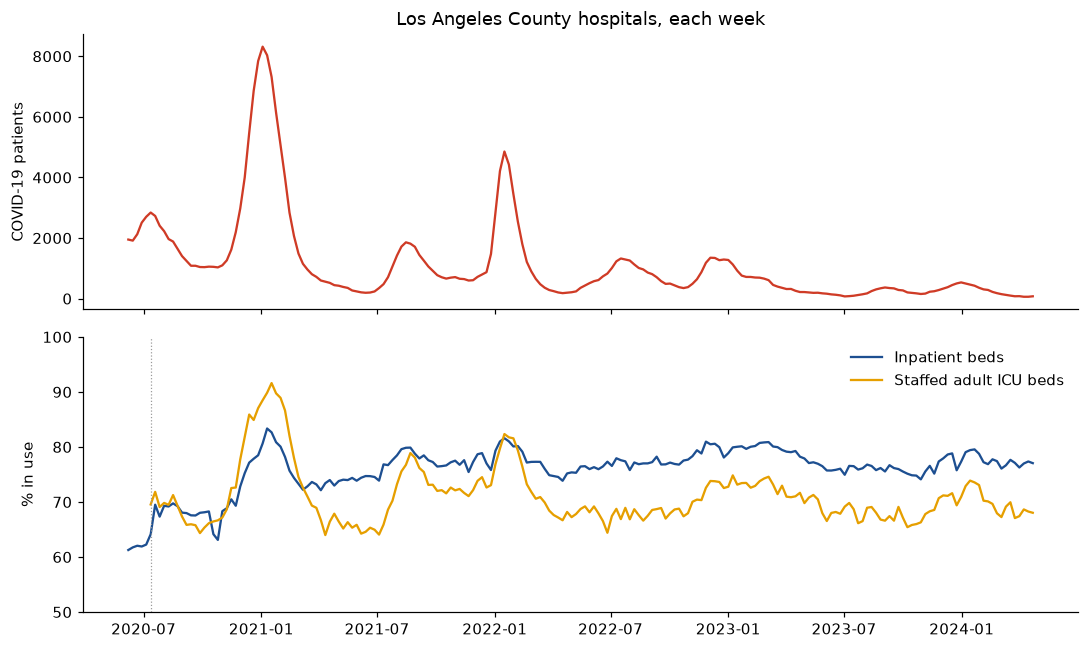

In [2]:
g = w.groupby('week').agg(hospitals=('hospital_pk', 'nunique'), beds=('beds', 'sum'), beds_used=('beds_used', 'sum'), covid=('covid_patients', 'sum'), icu_beds=('icu_beds', 'sum'), icu_used=('icu_used', 'sum'))
g['in_use'] = 100 * g.beds_used / g.beds; g['icu_in_use'] = 100 * g.icu_used / g.icu_beds
peak = g.covid.idxmax()
print(f"Busiest week: {peak.date()}, {g.covid[peak]:,.0f} COVID-19 patients, {g.in_use[peak]:.1f}% of {g.beds[peak]:,.0f} beds in use, ICU {g.icu_in_use[peak]:.1f}%")
print(f"Fullest ICU week: {g.icu_in_use.idxmax().date()}, {g.icu_in_use.max():.1f}%")
m = pd.Timestamp('2023-03-05')
print(f"5 March 2023: {g.covid[m]:,.0f} COVID-19 patients, {g.in_use[m]:.1f}% of {g.beds[m]:,.0f} beds in use")
print(f"Beds reported: {g.beds[peak]:,.0f} in the peak week, surge beds included; {g.beds[m]:,.0f} on 5 March 2023 ({g.beds[peak] - g.beds[m]:,.0f} fewer)")
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(g.index, g.covid, color='#cf3b26'); ax[0].set_ylabel('COVID-19 patients')
ax[1].plot(g.index, g.in_use, label='Inpatient beds', color='#1d4f91'); ax[1].plot(g.index, g.icu_in_use, label='Staffed adult ICU beds', color='#e69f00')
ax[1].set_ylabel('% in use'); ax[1].legend(frameon=False); ax[1].set_ylim(50, 100)
# the bed counts step down in the week of 12 July 2020, the first week the file reports staffed ICU beds
ax[1].axvline(pd.Timestamp('2020-07-12'), color='#999', lw=0.8, ls=':')
ax[0].set_title('Los Angeles County hospitals, each week'); plt.tight_layout()

## 2. The surge week, hospital by hospital

In [3]:
pw = w[w.week == peak]
print(f"{(pw.occupancy >= 90).sum()} of {pw.occupancy.notna().sum()} hospitals reporting were 90% full or fuller; "
      f"{(pw.icu_occupancy >= 95).sum()} of {pw.icu_occupancy.notna().sum()} had their staffed adult ICU 95% full or fuller")

32 of 83 hospitals reporting were 90% full or fuller; 39 of 76 had their staffed adult ICU 95% full or fuller


## 3. After the pandemic

`occupancy_2023_24` is each hospital's beds in use over its beds, all weeks of 2023 and 2024 (to 21 April) added up.

In [4]:
gen = h[h.type.isin(['General (short term)', 'Critical access'])]
print(f"{(gen.occupancy_2023_24 >= 90).sum()} of {gen.occupancy_2023_24.notna().sum()} general hospitals averaged 90% or fuller")
big = gen[gen.beds_2023_24 >= 100].sort_values('occupancy_2023_24', ascending=False)
big[['name', 'city', 'beds_2023_24', 'occupancy_2023_24', 'occupancy_surge', 'weeks_90']].head(12)

16 of 74 general hospitals averaged 90% or fuller


,name,city,beds_2023_24,occupancy_2023_24,occupancy_surge,weeks_90
73,"Martin Luther King, Jr. Community Hospital",Los Angeles,131.0,98.1,86.3,75
29,Ronald Reagan UCLA Medical Center,Los Angeles,424.0,97.5,91.6,193
27,USC Arcadia Hospital,Arcadia,207.9,96.8,96.2,193
18,City of Hope Helford Clinical Research Hospital,Duarte,233.0,96.2,97.9,203
30,Providence Holy Cross Medical Center,Mission Hills,262.1,95.6,95.2,170
1,Antelope Valley Hospital,Lancaster,261.0,95.4,94.9,190
28,Glendale Adventist Medical Center,Glendale,274.4,94.6,95.2,163
57,Keck Hospital of USC,Los Angeles,268.6,93.5,93.6,192
8,Saint Francis Medical Center,Lynwood,267.7,93.4,90.4,166
9,Santa Monica - UCLA Med Ctr & Orthopaedic Hosp...,Santa Monica,268.0,93.0,84.7,109


In [5]:
check = w.groupby('hospital_pk').apply(lambda d: int((d.occupancy >= 90).sum()), include_groups=False)
assert (h.set_index('hospital_pk').weeks_90 == check.reindex(h.hospital_pk).fillna(0).astype(int).values).all()
print("weeks_90 matches the weekly table (Plotlay's formula column count(occupancy >= 90) gives the same)")

weeks_90 matches the weekly table (Plotlay's formula column count(occupancy >= 90) gives the same)


## 4. How far people live from a general hospital

`nearest_km` is the straight line from a point inside each tract to the nearest general hospital (short term or
critical access) reporting in 2023-24. It is not a drive: freeways, hills and the traffic make a drive longer.

In [6]:
pop = t.population.sum()
bands = ['0 to 2 km', '2 to 5 km', '5 to 10 km', '10 to 20 km', '20 km or more']
b = t.groupby('band').population.sum().reindex(bands)
print((b / pop * 100).round(1).to_string())
o = t.sort_values('nearest_km'); med = o.nearest_km[o.population.cumsum() >= pop / 2].iloc[0]
print(f"{pop:,} residents; half within {med:.2f} km; the average resident {np.average(t.nearest_km, weights=t.population + 1e-9):.2f} km; {t[t.nearest_km >= 10].population.sum():,} live 10 km or more away")
av = t[t.nearest_hospital.isin(['Antelope Valley Hospital', 'Palmdale Regional Medical Center'])]
print(f"Antelope Valley: {av.population.sum():,} people, {np.average(av.nearest_km, weights=av.population + 1e-9):.2f} km on average, "
      f"{np.average(av.beds_per_1000_10km, weights=av.population + 1e-9):.2f} beds per 1,000 within 10 km (county {np.average(t.beds_per_1000_10km, weights=t.population + 1e-9):.2f})")

band
0 to 2 km        30.3
2 to 5 km        52.6
5 to 10 km       14.5
10 to 20 km       2.2
20 km or more     0.5
9,936,690 residents; half within 2.84 km; the average resident 3.43 km; 258,746 live 10 km or more away
Antelope Valley: 411,291 people, 7.58 km on average, 1.09 beds per 1,000 within 10 km (county 1.67)


Text(0.5, 1.0, 'Los Angeles County census tracts')

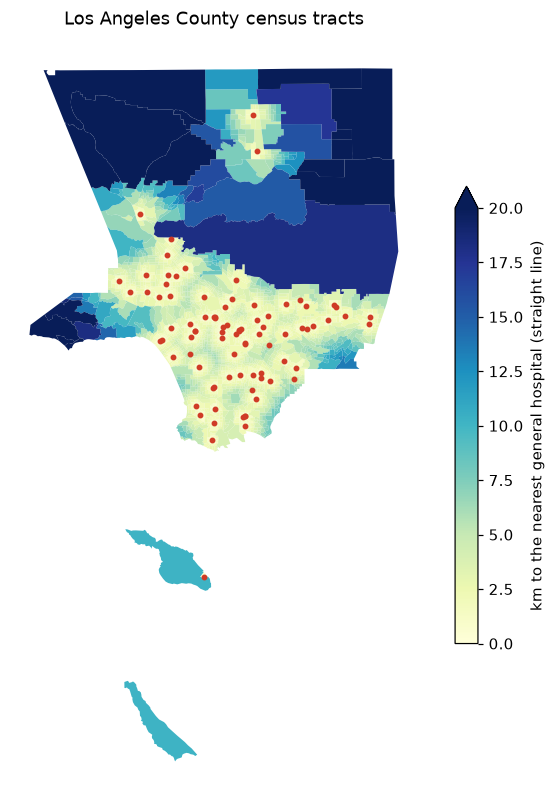

In [7]:
tr = gpd.read_file(f'{DATA}/geometry/tracts.geojson').merge(t[['geoid', 'nearest_km']], left_on='key', right_on='geoid')
hs = gpd.read_file(f'{DATA}/geometry/hospitals.geojson')
ax = tr.plot(column='nearest_km', cmap='YlGnBu', scheme=None, vmin=0, vmax=20, figsize=(9, 9), legend=True, legend_kwds={'label': 'km to the nearest general hospital (straight line)', 'shrink': .6})
hs.to_crs(3310).centroid.to_crs(4326).plot(ax=ax, color='#cf3b26', markersize=8); ax.set_axis_off(); ax.set_title('Los Angeles County census tracts')

## 5. Check against Plotlay's export

The data layer's linked data, exported from Plotlay, has the same weeks for the same keys.

In [8]:
import glob, os
f = sorted(glob.glob(f'{DATA}/geometry/hospitals.geojson'))[0]
keys = set(gpd.read_file(f).key.astype(str))
print(len(keys), 'hospital shapes;', 'all keyed to a row of hospitals.csv:', keys == set(h.hospital_pk))

86 hospital shapes; all keyed to a row of hospitals.csv: True


## Read it carefully

- **The data stopped in May 2024**, when hospitals no longer had to report. A week is a 7-day average, Sunday to Saturday.
- **Beds are what each hospital reported**: staffed inpatient beds, surge and overflow beds included. The count fell
  after the surge, so a share in use can hold steady with fewer patients.
- **Small counts are suppressed** by HHS (-999999 in the source): blank here, never zero.
- **Two records are not hospitals of their own**: 05T782 repeated Casa Colina week for week from December 2022 (dropped);
  05T485 was a 42-bed temporary site at Long Beach Medical Center in late 2020 (added to that hospital).
- **Distances are straight lines**, not drive times. Beds per 1,000 within 10 km ignores the county line, so the edges
  read low.